In [1]:
import time, torch, pandas as pd
from PIL import Image
from plantdata import load_classes, eval_transform
from plantmodel import CropMaskedResNet
from gradcam import GradCAM

class_ids, crops, crop_mask = load_classes("splits_v2")
ck = torch.load("checkpoints/R15.pt", map_location="cpu", weights_only=False)
model = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
model.load_state_dict(ck["state_dict"])
explainer = GradCAM(model)

manifest = pd.read_csv("cache_256/cached_manifest.csv")
row = manifest[manifest.split == "val_wild"].iloc[0]
image = eval_transform()(Image.open("cache_256/" + row.cache_path).convert("RGB")).unsqueeze(0)
crop = torch.tensor([crops.index(row.crop)])

start = time.perf_counter()
cam, k, logits = explainer(image, crop)
print(f"heatmap {tuple(cam.shape)}, values {cam.min():.2f} to {cam.max():.2f}, {1000*(time.perf_counter()-start):.0f} ms")
print("explained class:", class_ids[k], "| true class:", row.class_id)
print("parameter gradients left behind:", any(p.grad is not None for p in model.parameters()))
with torch.no_grad():
    print("ordinary prediction still works:", tuple(model(image, crop).shape))

heatmap (224, 224), values 0.00 to 1.00, 172 ms
explained class: apple_scab | true class: apple_scab
parameter gradients left behind: False
ordinary prediction still works: (1, 20)


                       class_id                       pred  confidence  correct                                                       rel_path
980          potato_late_blight         potato_late_blight    0.949333     True   train/Potato leaf late blight/potatolb_upper_leafcux1200.jpg
751               grape_healthy              grape_healthy    0.627304     True            train/grape leaf/4635766-green-grapevine-leaves.jpg
447   corn_northern_leaf_blight  corn_northern_leaf_blight    0.432781     True  train/Corn leaf blight/Fig1_Northern_corn_leaf_blight.JPG.jpg
1487        tomato_mosaic_virus         tomato_late_blight    0.454050    False               train/Tomato leaf mosaic virus/mosiac-virus3.jpg
1458        tomato_mosaic_virus        tomato_early_blight    0.389505    False                     test/Tomato leaf mosaic virus/9511.img.jpg
265       pepper_bacterial_spot             pepper_healthy    0.716172    False                         train/Bell_pepper leaf spot/ed8e20.jpg

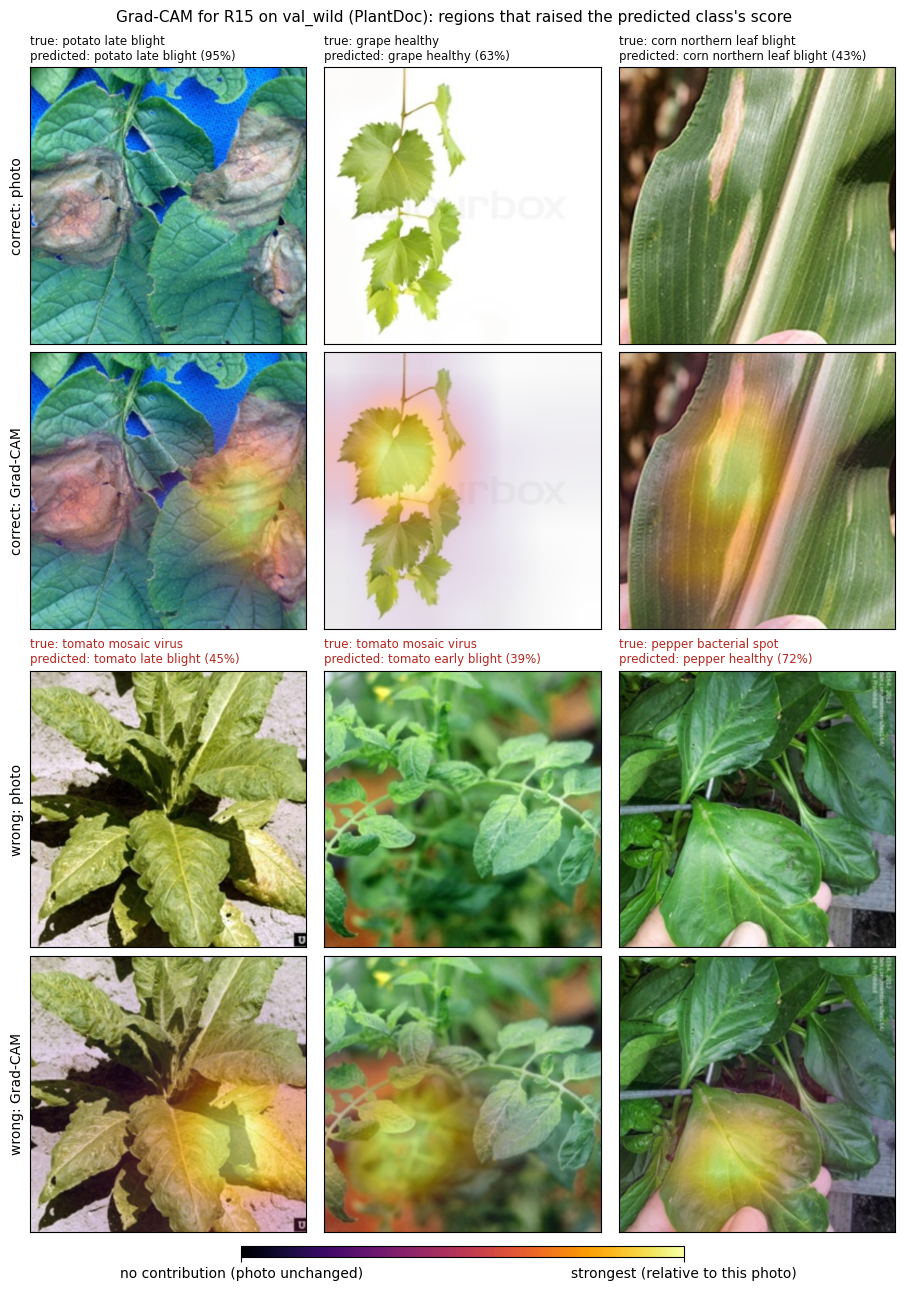

In [2]:
import json
import matplotlib.pyplot as plt
from pathlib import Path
from plantdata import read_manifest, PlantDataset, make_loader
from calibration import collect_logits
from gradcam import overlay

CACHE_DIR = Path("cache_256")
manifest = read_manifest(CACHE_DIR)
T = json.loads(Path("checkpoints/R15_calibration.json").read_text())["temperature"]
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

dataset = PlantDataset(manifest, "val_wild", CACHE_DIR, crops, eval_transform())
logits, labels = collect_logits(model, make_loader(dataset, batch_size=128, train=False, num_workers=0), device)
probs = (logits / T).softmax(dim=1)
val = dataset.info.reset_index(drop=True).copy()
val["pred"] = [class_ids[k] for k in probs.argmax(dim=1)]
val["confidence"] = probs.max(dim=1).values.numpy()
val["correct"] = val.pred == val.class_id

picked = pd.concat([val[val.correct].sample(3, random_state=42), val[~val.correct].sample(3, random_state=42)])
picked.to_csv("results/q5_gradcam_examples.csv")

model.cpu()
fig, axes = plt.subplots(4, 3, figsize=(9, 12.8), layout="constrained")
for n, (i, row) in enumerate(picked.iterrows()):
    photo = Image.open(dataset.paths[i]).convert("RGB")
    image, crop, _ = dataset[i]
    cam, k, _ = explainer(image.unsqueeze(0), crop.view(1))
    view, heat = overlay(photo, cam)
    r, c = 2 * (n // 3), n % 3
    axes[r, c].imshow(view)
    axes[r + 1, c].imshow(heat)
    true_name, pred_name = row.class_id.replace("_", " "), class_ids[k].replace("_", " ")
    axes[r, c].set_title(f"true: {true_name}\npredicted: {pred_name} ({row.confidence:.0%})", fontsize=8.5,
                         color="#0b0b0b" if row.correct else "#b3261e", loc="left")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
for r, label in [(0, "correct: photo"), (1, "correct: Grad-CAM"), (2, "wrong: photo"), (3, "wrong: Grad-CAM")]:
    axes[r, 0].set_ylabel(label, fontsize=10)
sm = plt.cm.ScalarMappable(cmap="inferno")
cbar = fig.colorbar(sm, ax=axes[-1, :], orientation="horizontal", fraction=0.04, aspect=40)
cbar.set_ticks([0, 1], labels=["no contribution (photo unchanged)", "strongest (relative to this photo)"])
fig.suptitle("Grad-CAM for R15 on val_wild (PlantDoc): regions that raised the predicted class's score",
             fontsize=11)
fig.savefig("figures/q5_gradcam_examples.png", dpi=200, bbox_inches="tight")
model.to(device)
print(picked[["class_id", "pred", "confidence", "correct", "rel_path"]].to_string())

Sanity check

In [3]:
import time
FRACTION = 0.20                                   # share of the image hidden in each test
model.to(device).eval()

def region(cam, fraction, top=True):
    """Exactly `fraction` of the pixels: the hottest (top=True) or the coldest of the heatmap."""
    order = cam.flatten().argsort(descending=top)
    mask = torch.zeros(cam.numel(), dtype=torch.bool)
    mask[order[: int(fraction * cam.numel())]] = True
    return mask.view(cam.shape)

start = time.perf_counter()
hot, cold, explained, p_original = [], [], [], []
for i in range(len(dataset)):
    image, crop, _ = dataset[i]
    cam, k, logits = explainer(image.unsqueeze(0).to(device), crop.view(1).to(device))
    hot.append(region(cam, FRACTION, top=True))
    cold.append(region(cam, FRACTION, top=False))
    explained.append(k)
    p_original.append(float((logits / T).softmax(dim=0)[k]))

other = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(42))
rows = []
with torch.no_grad():
    for i in range(len(dataset)):
        image, crop, _ = dataset[i]
        hidden = image.repeat(3, 1, 1, 1)                 # three copies of the photo
        for copy, mask in enumerate([hot[i], hot[int(other[i])], cold[i]]):
            hidden[copy][:, mask] = 0.0                   # 0 = the average ImageNet colour after normalising
        probs = (model(hidden.to(device), crop.repeat(3).to(device)).float().cpu() / T).softmax(dim=1)
        k = explained[i]
        rows.append({"p_original": p_original[i],
                     "p_hot": float(probs[0, k]), "p_random": float(probs[1, k]), "p_cold": float(probs[2, k]),
                     "changed_hot": int(probs[0].argmax()) != k, "changed_random": int(probs[1].argmax()) != k,
                     "changed_cold": int(probs[2].argmax()) != k})
deletion = pd.DataFrame(rows)
deletion.to_csv("results/q5_deletion_val_wild.csv", index=False)

summary = pd.DataFrame([{
    "hidden region": name,
    "mean drop in probability": round((deletion.p_original - deletion[f"p_{key}"]).mean(), 3),
    "predictions changed": f"{deletion[f'changed_{key}'].mean():.0%}"}
    for key, name in [("hot", "hottest 20% (Grad-CAM)"), ("random", "random 20% (another photo's hot region)"),
                      ("cold", "coldest 20% (Grad-CAM)")]])
print(f"{len(deletion)} val_wild photos, {time.perf_counter() - start:.0f} s")
print(summary.to_string(index=False))
print(f"hot drop > random drop in {((deletion.p_original - deletion.p_hot) > (deletion.p_original - deletion.p_random)).mean():.0%} of photos")

1630 val_wild photos, 47 s
                          hidden region  mean drop in probability predictions changed
                 hottest 20% (Grad-CAM)                     0.091                 41%
random 20% (another photo's hot region)                     0.026                 26%
                 coldest 20% (Grad-CAM)                    -0.030                 10%
hot drop > random drop in 78% of photos


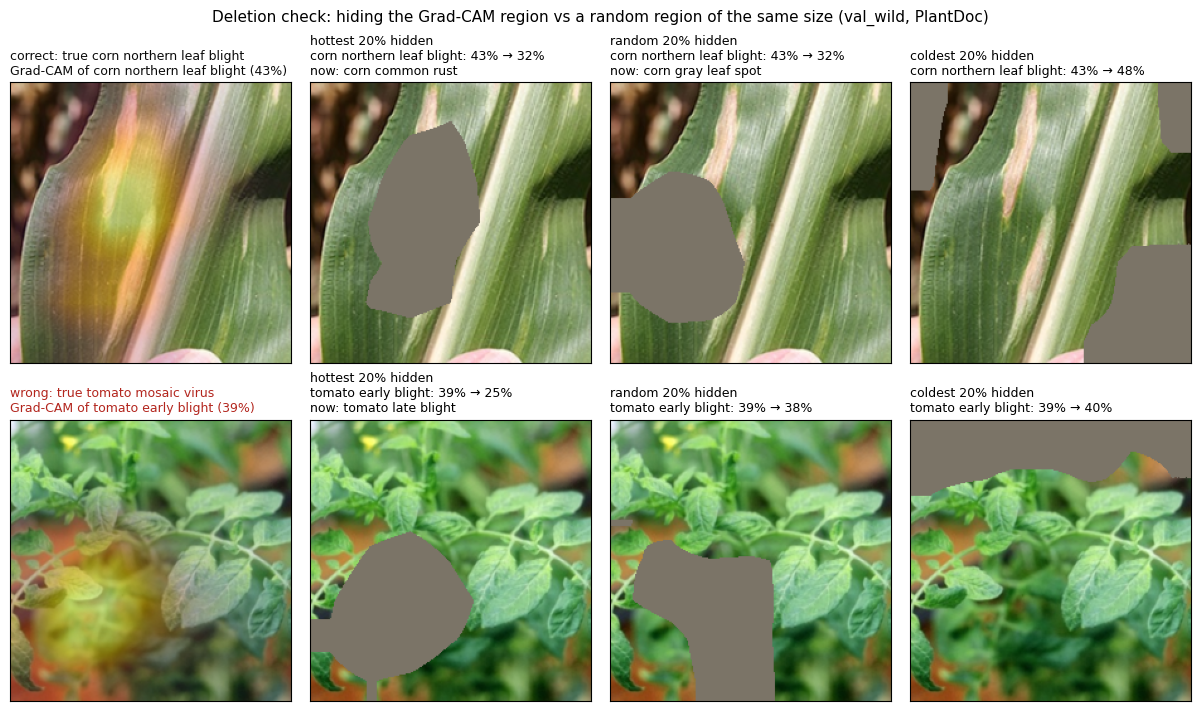

In [5]:
import numpy as np
from gradcam import model_view
MEAN_COLOUR = np.array([0.485, 0.456, 0.406]) * 255    # what "0" means after normalising, for display
cases = {"correct": 447, "wrong": 1458}

def nice(k):
    return class_ids[k].replace("_", " ")

fig, axes = plt.subplots(2, 4, figsize=(12, 7), layout="constrained")
for r, (label, i) in enumerate(cases.items()):
    image, crop, _ = dataset[i]
    photo = Image.open(dataset.paths[i]).convert("RGB")
    cam, k, logits = explainer(image.unsqueeze(0).to(device), crop.view(1).to(device))
    p0 = float((logits / T).softmax(dim=0)[k])
    view = np.asarray(model_view(photo, 224)).astype(float)
    masks = [hot[i], hot[int(other[i])], cold[i]]
    hidden = image.repeat(3, 1, 1, 1)
    for copy, mask in enumerate(masks):
        hidden[copy][:, mask] = 0.0
    with torch.no_grad():
        probs = (model(hidden.to(device), crop.repeat(3).to(device)).float().cpu() / T).softmax(dim=1)

    axes[r, 0].imshow(overlay(photo, cam, size=224)[1])
    axes[r, 0].set_title(f"{label}: true {nice(int(dataset.labels[i]))}\nGrad-CAM of {nice(k)} ({p0:.0%})",
                         fontsize=9, loc="left", color="#0b0b0b" if label == "correct" else "#b3261e")
    for c, (mask, name) in enumerate(zip(masks, ["hottest 20% hidden", "random 20% hidden", "coldest 20% hidden"]), 1):
        shown = view.copy()
        shown[mask.numpy()] = MEAN_COLOUR
        axes[r, c].imshow(shown.astype(np.uint8))
        top = int(probs[c - 1].argmax())
        axes[r, c].set_title(f"{name}\n{nice(k)}: {p0:.0%} → {probs[c - 1, k]:.0%}"
                             + ("" if top == k else f"\nnow: {nice(top)}"), fontsize=9, loc="left")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Deletion check: hiding the Grad-CAM region vs a random region of the same size (val_wild, PlantDoc)",
             fontsize=11)
fig.savefig("figures/q5_deletion_cases.png", dpi=200, bbox_inches="tight")

Model randomisation

300 val_wild photos, 23 s
                        model  mean rank correlation with R15's map empty maps
               R15 (deployed)                                 1.000         0%
R21 (same recipe, other seed)                                 0.748         0%
            random up to head                                 0.120         6%
          random up to layer4                                -0.000         4%
          random up to layer3                                 0.032        12%
          random up to layer2                                 0.047        16%
          random up to layer1                                 0.080        22%
            random up to stem                                 0.044        18%


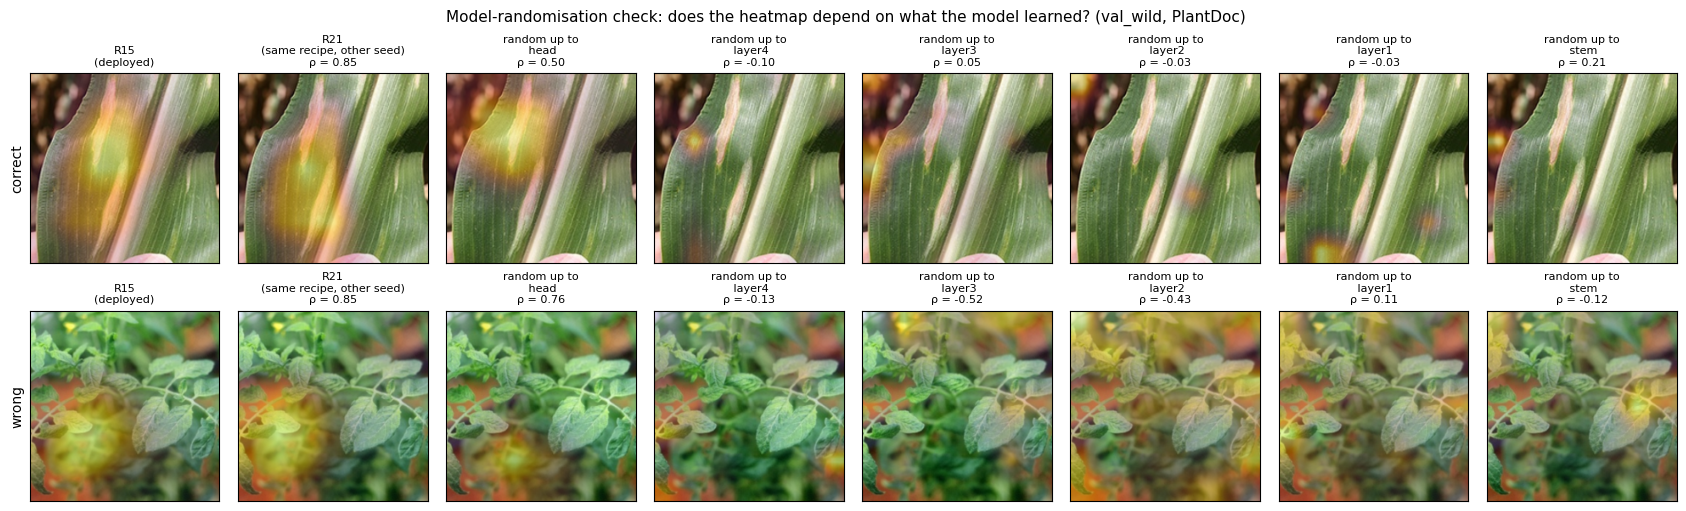

In [6]:
import torch.nn.functional as F
from scipy.stats import spearmanr
from plantmodel import CropMaskedResNet

N_PHOTOS = 300
STEPS = ["head", "layer4", "layer3", "layer2", "layer1", "stem"]   # randomised from the output backwards

def load_model(run_id):
    ck = torch.load(f"checkpoints/{run_id}.pt", map_location="cpu", weights_only=False)
    m = CropMaskedResNet(ck["config"]["depth"], crop_mask, pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(device).eval()

def randomised(upto):
    """R15 with every layer from the head back to `upto` reset to fresh random weights."""
    m = load_model("R15")
    torch.manual_seed(0)
    parts = {"head": [m.head], "layer4": [m.backbone.layer4], "layer3": [m.backbone.layer3],
             "layer2": [m.backbone.layer2], "layer1": [m.backbone.layer1], "stem": [m.backbone.conv1, m.backbone.bn1]}
    for step in STEPS[: STEPS.index(upto) + 1]:
        for part in parts[step]:
            for module in part.modules():
                if hasattr(module, "reset_parameters"):
                    module.reset_parameters()
    return m

def shrink(cam, cell):
    """The heatmap averaged over cell x cell pixel blocks (224 / 4 = 56 x 56 to keep, 224 / 8 = 28 x 28 to compare)."""
    return F.avg_pool2d(cam[None, None], cell)[0, 0]

def small(cam56):
    return shrink(cam56, 2).flatten().numpy()

model.to(device).eval()
explainers = {"R15 (deployed)": explainer, "R21 (same recipe, other seed)": GradCAM(load_model("R21"))}
for step in STEPS:
    explainers[f"random up to {step}"] = GradCAM(randomised(step))

sample = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(42))[:N_PHOTOS].tolist()
photos = sample + [i for i in cases.values() if i not in sample]
start = time.perf_counter()
maps = {name: {} for name in explainers}
for i in photos:
    image, crop, _ = dataset[i]
    x, c = image.unsqueeze(0).to(device), crop.view(1).to(device)
    cam, k, _ = explainer(x, c)                       # R15 chooses the class to explain ...
    maps["R15 (deployed)"][i] = shrink(cam, 4)
    for name, ex in explainers.items():
        if name != "R15 (deployed)":
            maps[name][i] = shrink(ex(x, c, class_idx=k)[0], 4)   # ... every other model explains the same class

rows = []
for name in explainers:
    rho, empty = [], 0
    for i in sample:
        a, b = small(maps["R15 (deployed)"][i]), small(maps[name][i])
        if b.max() == 0 or a.max() == 0:
            empty += 1
            continue
        rho.append(spearmanr(a, b).statistic)
    rows.append({"model": name, "mean rank correlation with R15's map": round(float(np.mean(rho)), 3),
                 "empty maps": f"{empty / len(sample):.0%}"})
randomisation = pd.DataFrame(rows)
randomisation.to_csv("results/q5_randomisation_val_wild.csv", index=False)
print(f"{len(sample)} val_wild photos, {time.perf_counter() - start:.0f} s")
print(randomisation.to_string(index=False))

fig, axes = plt.subplots(len(cases), len(explainers), figsize=(2.1 * len(explainers), 2.5 * len(cases)),
                         layout="constrained")
for r, (label, i) in enumerate(cases.items()):
    photo = Image.open(dataset.paths[i]).convert("RGB")
    for c, name in enumerate(explainers):
        axes[r, c].imshow(overlay(photo, maps[name][i], size=224)[1])
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        rho = "" if c == 0 or maps[name][i].max() == 0 else \
            f"\nρ = {spearmanr(small(maps['R15 (deployed)'][i]), small(maps[name][i])).statistic:.2f}"
        axes[r, c].set_title(name.replace(" (", "\n(").replace("random up to", "random up to\n") + rho, fontsize=8)
    axes[r, 0].set_ylabel(label, fontsize=10)
fig.suptitle("Model-randomisation check: does the heatmap depend on what the model learned? (val_wild, PlantDoc)",
             fontsize=11)
fig.savefig("figures/q5_randomisation.png", dpi=200, bbox_inches="tight")

this photo:
                    class  probability
      tomato_early_blight        0.390
       tomato_late_blight        0.147
  tomato_yellow_leaf_curl        0.146
         tomato_leaf_mold        0.093
    tomato_bacterial_spot        0.068
tomato_septoria_leaf_spot        0.055
           tomato_healthy        0.052
      tomato_mosaic_virus        0.048

val_wild tomato_mosaic_virus: 49 photos, recall 0.02
pred
tomato_late_blight           19
tomato_early_blight          12
tomato_yellow_leaf_curl      11
tomato_leaf_mold              2
tomato_septoria_leaf_spot     2
tomato_healthy                1
tomato_bacterial_spot         1
tomato_mosaic_virus           1

training photos per tomato class (PlantVillage):
class_id
tomato_yellow_leaf_curl      3750
tomato_bacterial_spot        1488
tomato_late_blight           1336
tomato_septoria_leaf_spot    1240
tomato_healthy               1114
tomato_early_blight           700
tomato_leaf_mold              664
tomato_mosaic_virus      

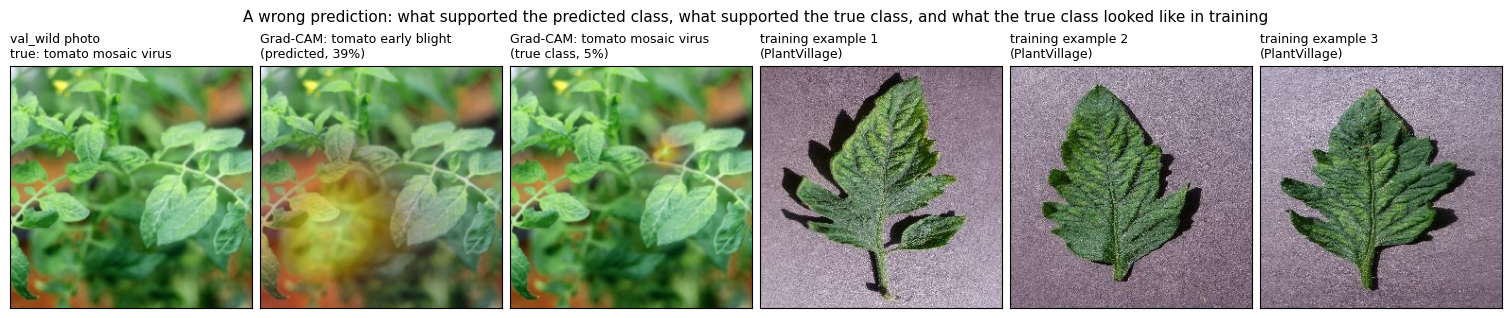

In [7]:
from gradcam import overlay

i = 1458                                                    # tomato mosaic virus, predicted early blight
true_k = int(dataset.labels[i])
image, crop, _ = dataset[i]
x, c = image.unsqueeze(0).to(device), crop.view(1).to(device)
cam_pred, pred_k, logits_i = explainer(x, c)
cam_true, _, _ = explainer(x, c, class_idx=true_k)
p = (logits_i / T).softmax(dim=0)

# 1. how the model ranked this crop's classes for this photo
crop_classes = [k for k in range(len(class_ids)) if crop_mask[int(crop), k]]
ranking = pd.DataFrame({"class": [class_ids[k] for k in crop_classes],
                        "probability": [round(float(p[k]), 3) for k in crop_classes]}).sort_values("probability", ascending=False)
print("this photo:\n" + ranking.to_string(index=False))

# 2. is this error typical? where do all val_wild mosaic photos go, and how many mosaic photos did the model train on?
mosaic = val[val.class_id == class_ids[true_k]]
print(f"\nval_wild {class_ids[true_k]}: {len(mosaic)} photos, recall {(mosaic.pred == mosaic.class_id).mean():.2f}")
print(mosaic.pred.value_counts().to_string())
train = manifest[manifest.split == "train"]
tomato_counts = train[train.crop == "tomato"].class_id.value_counts()
print("\ntraining photos per tomato class (PlantVillage):\n" + tomato_counts.to_string())

# 3. figure: the photo, both explanations, and what mosaic looked like in training
examples = train[train.class_id == class_ids[true_k]].sample(3, random_state=42)
photo = Image.open(dataset.paths[i]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(15, 3.4), layout="constrained")
panels = [(overlay(photo, cam_pred, size=224)[0], f"val_wild photo\ntrue: {class_ids[true_k].replace('_', ' ')}"),
          (overlay(photo, cam_pred, size=224)[1], f"Grad-CAM: {class_ids[pred_k].replace('_', ' ')}\n(predicted, {p[pred_k]:.0%})"),
          (overlay(photo, cam_true, size=224)[1], f"Grad-CAM: {class_ids[true_k].replace('_', ' ')}\n(true class, {p[true_k]:.0%})")]
panels += [(Image.open(CACHE_DIR / row.cache_path).convert("RGB"), f"training example {n + 1}\n(PlantVillage)")
           for n, (_, row) in enumerate(examples.iterrows())]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=9, loc="left")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("A wrong prediction: what supported the predicted class, what supported the true class, "
             "and what the true class looked like in training", fontsize=11)
fig.savefig("figures/q5_wrong_prediction.png", dpi=200, bbox_inches="tight")